# Quantum Finance — Credit Scoring com Regressão Linear Múltipla

**Disciplina:** Applied Statistics — Projeto Integrado
**Base:** `data/Base_ScoreCredito_QuantumFinance.csv` (10.127 clientes)
**Variável target:** `SCORE_CREDITO`

A Quantum Finance observa crescimento da inadimplência e quer aprimorar seu modelo de crédito para atrair clientes de **baixo risco**.
O desafio é desenvolver um modelo preditivo do `SCORE_CREDITO` e um **simulador** para analistas de crédito e gerentes de conta.

**Roteiro do notebook**

| Etapa | Conteúdo |
|---|---|
| 1–2 | Quadro conceitual e carga dos dados |
| 3 | Preparação dos dados (ausentes, outliers, dummies) |
| 4 | Análise descritiva |
| 5 | Análise de correlação |
| 6 | Modelo de regressão linear múltipla (treino/teste 70/30, seleção *stepwise*) |
| 7 | Verificação das suposições da regressão |
| 8 | Qualidade e erros do modelo |
| 9 | Árvore de decisão (regressão) e comparação |
| 10 | Simulador (função Python, planilha Excel e app Streamlit) |

## 1. Quadro conceitual estatístico

| Componente | Descrição |
|---|---|
| **Tema** | Concessão de crédito ao consumidor — *Credit Scoring* |
| **Problema** | Aumento da inadimplência; o modelo de crédito atual não diferencia bem clientes de baixo e alto risco |
| **Objetivo** | Estimar o `SCORE_CREDITO` de um cliente a partir de seu perfil e disponibilizar um simulador |
| **Unidade de análise** | Cliente da carteira da Quantum Finance |
| **Variável resposta (Y)** | `SCORE_CREDITO` — quantitativa contínua |
| **Variáveis explicativas (X)** | Idade, sexo, estado civil, escolaridade, dependentes, tempo de serviço, trabalha, salário, região de moradia, casa própria, valor do imóvel, cartões e carros |
| **Hipóteses** | H0: βj = 0 (a variável não influencia o score) × H1: βj ≠ 0 |
| **Técnica** | Regressão linear múltipla (MQO), comparada a uma árvore de decisão de regressão |
| **Nível de significância** | α = 5% |
| **Métricas** | R², R² ajustado, RMSE, MAE e MAPE na base de teste |

## 2. Carga dos dados

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

SEED = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 50)

In [2]:
# Localiza o CSV (funciona rodando a partir de notebook/ ou da raiz do repositório)
DATA_DIR = next(p for p in [Path("../data"), Path("data")] if p.exists())
csv_path = sorted(DATA_DIR.glob("Base_ScoreCredito_QuantumFinance*.csv"))[0]

# keep_default_na=False: "na" em estado_civil é uma categoria ("não informado"), não um valor ausente
df_raw = pd.read_csv(csv_path, sep=";", decimal=",", keep_default_na=False)
print(f"Arquivo: {csv_path.name} | {df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")
df_raw.head()

Arquivo: Base_ScoreCredito_QuantumFinance(10).csv | 10,127 linhas x 15 colunas


,id,idade,sexo,estado_civil,escola,Qte_dependentes,tempo_ultimoservico,trabalha,vl_salario_mil,reg_moradia,casa_propria,vl_imovel_em_mil,Qte_cartoes,Qte_carros,SCORE_CREDITO
0,708082083,45,F,casado,graduacao,3,40,1,40.0897,3,0,0,1,1,778.0000
1,708083283,58,M,solteiro,ensino fundam,0,44,1,66.5576,3,0,0,1,0,276.3000
2,708084558,46,M,divorciado,doutorado,3,35,1,123.6818,6,0,0,1,1,401.0000
3,708085458,34,F,solteiro,mestrado,0,22,1,19.7159,6,0,0,1,0,347.4000
4,708086958,49,F,casado,mestrado,2,36,0,0.0000,3,1,437,1,2,476.0000


**Dicionário de variáveis**

| Variável | Tipo | Descrição |
|---|---|---|
| `id` | identificador | Código do cliente (não entra no modelo) |
| `idade` | numérica | Idade (anos) |
| `sexo` | categórica | F / M |
| `estado_civil` | categórica | casado, solteiro, divorciado, na (não informado) |
| `escola` | categórica | ensino fundam, ensino medio, graduacao, mestrado, doutorado |
| `Qte_dependentes` | numérica | Número de dependentes |
| `tempo_ultimoservico` | numérica | Tempo no último serviço |
| `trabalha` | binária (0/1) | Está trabalhando |
| `vl_salario_mil` | numérica | Salário (R$ mil) |
| `reg_moradia` | **categórica** (1 a 6) | Código da região de moradia — é um rótulo, não uma quantidade |
| `casa_propria` | binária (0/1) | Possui casa própria |
| `vl_imovel_em_mil` | numérica | Valor do imóvel (R$ mil) |
| `Qte_cartoes` | numérica | Quantidade de cartões |
| `Qte_carros` | numérica | Quantidade de carros |
| `SCORE_CREDITO` | numérica (**target**) | Score de crédito |

## 3. Preparação dos dados

### 3.1 Tipos, valores ausentes e duplicados

In [3]:
TARGET = "SCORE_CREDITO"
num_cols = ["idade", "vl_salario_mil", "vl_imovel_em_mil", "tempo_ultimoservico",
            "Qte_cartoes", "Qte_carros", "Qte_dependentes"]
bin_cols = ["trabalha", "casa_propria"]
cat_cols = ["sexo", "estado_civil", "escola", "reg_moradia"]

df = df_raw.drop(columns="id").copy()
df["reg_moradia"] = df["reg_moradia"].astype(str)   # região é categórica, mesmo sendo número

df.info()
ausentes = pd.DataFrame({"ausentes": df.isna().sum(),
                         "vazios ('')": (df.astype(str).apply(lambda s: s.str.strip()) == "").sum()})
print("\nIDs duplicados:", df_raw["id"].duplicated().sum(), "| Linhas duplicadas:", df.duplicated().sum())
ausentes.T

<class 'pandas.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   idade                10127 non-null  int64  
 1   sexo                 10127 non-null  str    
 2   estado_civil         10127 non-null  str    
 3   escola               10127 non-null  str    
 4   Qte_dependentes      10127 non-null  int64  
 5   tempo_ultimoservico  10127 non-null  int64  
 6   trabalha             10127 non-null  int64  
 7   vl_salario_mil       10127 non-null  float64
 8   reg_moradia          10127 non-null  str    
 9   casa_propria         10127 non-null  int64  
 10  vl_imovel_em_mil     10127 non-null  int64  
 11  Qte_cartoes          10127 non-null  int64  
 12  Qte_carros           10127 non-null  int64  
 13  SCORE_CREDITO        10127 non-null  float64
dtypes: float64(2), int64(8), str(4)
memory usage: 1.1 MB

IDs duplicados: 0 | Linhas duplicadas: 0


,idade,sexo,estado_civil,escola,Qte_dependentes,tempo_ultimoservico,trabalha,vl_salario_mil,reg_moradia,casa_propria,vl_imovel_em_mil,Qte_cartoes,Qte_carros,SCORE_CREDITO
ausentes,0,0,0,0,0,0,0,0,0,0,0,0,0,0
vazios (''),0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [4]:
for c in cat_cols + bin_cols:
    print(f"{c:13s} ->", dict(df[c].value_counts().sort_index()))

sexo          -> {'F': np.int64(5358), 'M': np.int64(4769)}
estado_civil  -> {'casado': np.int64(4687), 'divorciado': np.int64(748), 'na': np.int64(749), 'solteiro': np.int64(3943)}
escola        -> {'doutorado': np.int64(759), 'ensino fundam': np.int64(2283), 'ensino medio': np.int64(3352), 'graduacao': np.int64(2094), 'mestrado': np.int64(1639)}
reg_moradia   -> {'1': np.int64(1065), '2': np.int64(1164), '3': np.int64(2248), '4': np.int64(1923), '5': np.int64(1876), '6': np.int64(1851)}
trabalha      -> {0: np.int64(892), 1: np.int64(9235)}
casa_propria  -> {0: np.int64(6558), 1: np.int64(3569)}


- Não há valores ausentes (`NaN`) nem campos vazios, e não há clientes duplicados.
- Em `estado_civil` existe a categoria **`na`** (≈7% da base). Como é frequente e tem score próprio, ela é tratada como uma categoria a mais (“não informado”), e não como ausente — excluir essas linhas descartaria informação.

**Consistência entre variáveis** — zeros estruturais em salário e valor do imóvel:

In [5]:
display(df.groupby("trabalha")["vl_salario_mil"].describe())
display(df.groupby("casa_propria")["vl_imovel_em_mil"].describe())

,count,mean,std,min,25%,50%,75%,max
trabalha,,,,,,,,
0,892.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,"9,235.0000",76.9904,53.5145,13.4327,22.6872,69.9334,116.3391,233.3018


,count,mean,std,min,25%,50%,75%,max
casa_propria,,,,,,,,
0,"6,558.0000",0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
1,"3,569.0000",593.0328,422.8005,150.0000,269.0000,451.0000,784.0000,"1,800.0000"


- Quem **não trabalha** tem salário = 0 e quem **não tem casa própria** tem valor do imóvel = 0. São zeros estruturais (coerentes), não erros.
- Consequência: `trabalha`↔`vl_salario_mil` e `casa_propria`↔`vl_imovel_em_mil` carregam informação parecida — ponto de atenção para multicolinearidade (etapa 7).

### 3.2 Outliers (regra do IQR: abaixo de Q1 − 1,5·IQR ou acima de Q3 + 1,5·IQR)

In [6]:
def resumo_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((s < lim_inf) | (s > lim_sup)).sum()
    return pd.Series({"Q1": q1, "Q3": q3, "lim_inf": lim_inf, "lim_sup": lim_sup,
                      "n_outliers": n, "%_outliers": 100 * n / len(s), "min": s.min(), "max": s.max()})

outl = df[num_cols + [TARGET]].apply(resumo_outliers).T
outl

,Q1,Q3,lim_inf,lim_sup,n_outliers,%_outliers,min,max
idade,41.0000,52.0000,24.5000,68.5000,2.0000,0.0197,26.0000,73.0000
vl_salario_mil,21.3305,107.5442,-107.9900,236.8648,0.0000,0.0000,0.0000,233.3018
vl_imovel_em_mil,0.0000,289.0000,-433.5000,722.5000,"1,095.0000",10.8127,0.0000,"1,800.0000"
tempo_ultimoservico,30.0000,39.0000,16.5000,52.5000,427.0000,4.2165,7.0000,57.0000
Qte_cartoes,1.0000,1.0000,1.0000,1.0000,691.0000,6.8233,1.0000,4.0000
Qte_carros,0.0000,1.0000,-1.5000,2.5000,0.0000,0.0000,0.0000,2.0000
Qte_dependentes,0.0000,3.0000,-4.5000,7.5000,0.0000,0.0000,0.0000,5.0000
SCORE_CREDITO,375.0000,540.9000,126.1500,789.7500,248.0000,2.4489,162.0000,979.6500


,Q1,Q3,lim_inf,lim_sup,n_outliers,%_outliers,min,max
vl_imovel (proprietários),269.0000,784.0000,-503.5000,"1,556.5000",91.0000,2.5497,150.0000,"1,800.0000"


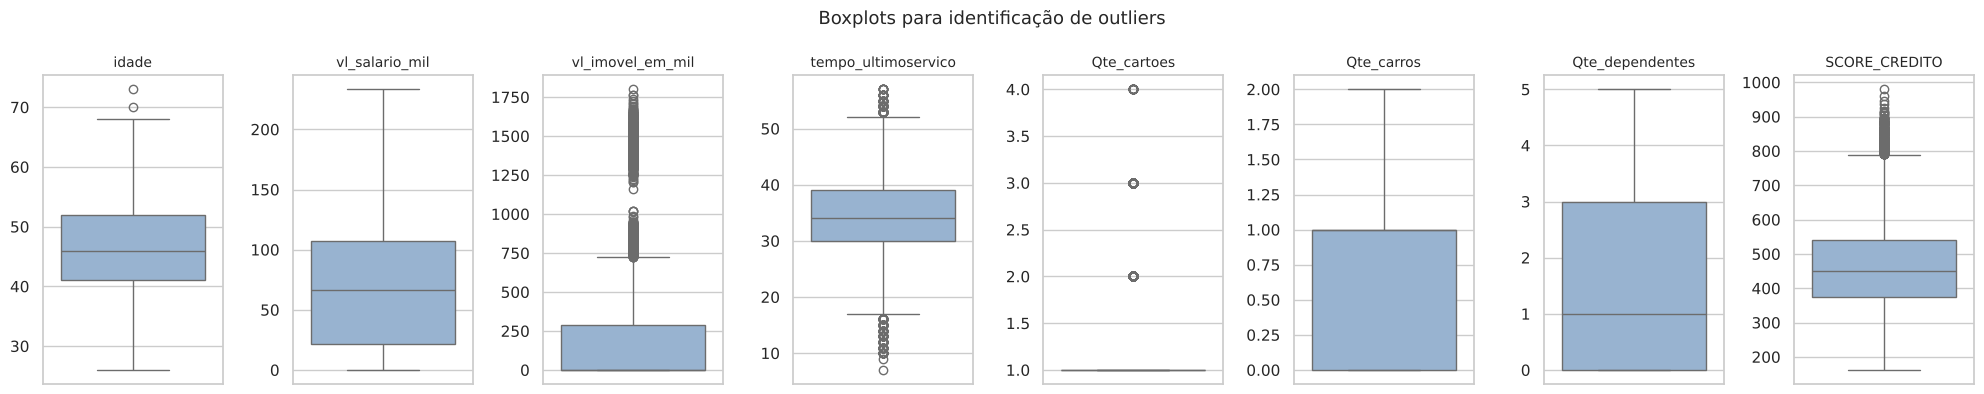

In [7]:
# Para o valor do imóvel, a regra do IQR na base toda é distorcida pelos zeros (65% não têm casa).
# Avaliamos só entre os proprietários:
display(resumo_outliers(df.loc[df.casa_propria == 1, "vl_imovel_em_mil"]).to_frame("vl_imovel (proprietários)").T)

fig, axes = plt.subplots(1, len(num_cols) + 1, figsize=(20, 4))
for ax, c in zip(axes, num_cols + [TARGET]):
    sns.boxplot(y=df[c], ax=ax, color="#8fb3d9"); ax.set_title(c, fontsize=10); ax.set_ylabel("")
plt.suptitle("Boxplots para identificação de outliers", fontsize=13); plt.tight_layout(); plt.show()

**Decisão sobre outliers:** os pontos sinalizados pelo IQR são valores **plausíveis** (clientes com mais cartões, imóveis caros, scores altos) e não erros de digitação.
Por isso **mantemos todas as observações** — removê-las tiraria justamente os perfis de baixo risco que a Quantum quer atrair.
A influência de pontos extremos no modelo é checada depois pela distância de Cook (etapa 7).

### 3.3 Variáveis dummies
`sexo`, `estado_civil`, `escola` e `reg_moradia` viram dummies com **k−1 colunas** (evita a armadilha das dummies / colinearidade perfeita com o intercepto).
Categorias de referência: `sexo = F`, `estado_civil = casado`, `escola = ensino fundam`, `reg_moradia = 1`.
`trabalha` e `casa_propria` já estão em 0/1 e entram como estão.

In [8]:
REFERENCIA = {"sexo": "F", "estado_civil": "casado", "escola": "ensino fundam", "reg_moradia": "1"}
CATEGORIAS = {c: [REFERENCIA[c]] + sorted(v for v in df[c].unique() if v != REFERENCIA[c]) for c in cat_cols}
CATEGORIAS["escola"] = ["ensino fundam", "ensino medio", "graduacao", "mestrado", "doutorado"]

def preparar_X(dados):
    # Aplica a mesma codificação a qualquer base (treino, teste ou cliente novo do simulador)
    d = dados.copy()
    for c in cat_cols:
        d[c] = pd.Categorical(d[c].astype(str), categories=CATEGORIAS[c])
    return pd.get_dummies(d[num_cols + bin_cols + cat_cols], columns=cat_cols, drop_first=True, dtype=float)

X = preparar_X(df)
y = df[TARGET]
print(X.shape[1], "variáveis explicativas após as dummies:")
print(list(X.columns))

22 variáveis explicativas após as dummies:
['idade', 'vl_salario_mil', 'vl_imovel_em_mil', 'tempo_ultimoservico', 'Qte_cartoes', 'Qte_carros', 'Qte_dependentes', 'trabalha', 'casa_propria', 'sexo_M', 'estado_civil_divorciado', 'estado_civil_na', 'estado_civil_solteiro', 'escola_ensino medio', 'escola_graduacao', 'escola_mestrado', 'escola_doutorado', 'reg_moradia_2', 'reg_moradia_3', 'reg_moradia_4', 'reg_moradia_5', 'reg_moradia_6']


## 4. Análise descritiva

### 4.1 Variáveis numéricas — média, mediana, desvio padrão, mínimo e máximo

In [9]:
desc_cols = num_cols + [TARGET]
desc = pd.DataFrame({
    "média": df[desc_cols].mean(), "mediana": df[desc_cols].median(), "desvio_padrão": df[desc_cols].std(),
    "mínimo": df[desc_cols].min(), "máximo": df[desc_cols].max(),
    "coef_variação_%": 100 * df[desc_cols].std() / df[desc_cols].mean(), "assimetria": df[desc_cols].skew(),
})
desc

,média,mediana,desvio_padrão,mínimo,máximo,coef_variação_%,assimetria
idade,46.3260,46.0000,8.0168,26.0000,73.0000,17.3052,-0.0336
vl_salario_mil,70.2090,66.4863,55.5670,0.0000,233.3018,79.1452,0.6598
vl_imovel_em_mil,208.9991,0.0000,378.4952,0.0000,"1,800.0000",181.0990,2.1794
tempo_ultimoservico,34.1332,34.0000,8.2214,7.0000,57.0000,24.0863,-0.0605
Qte_cartoes,1.0836,1.0000,0.3338,1.0000,4.0000,30.8022,4.6057
Qte_carros,0.6234,1.0000,0.5698,0.0000,2.0000,91.4038,0.2357
Qte_dependentes,1.5474,1.0000,1.4891,0.0000,5.0000,96.2281,0.5069
SCORE_CREDITO,469.5004,449.6000,133.8147,162.0000,979.6500,28.5015,0.7092


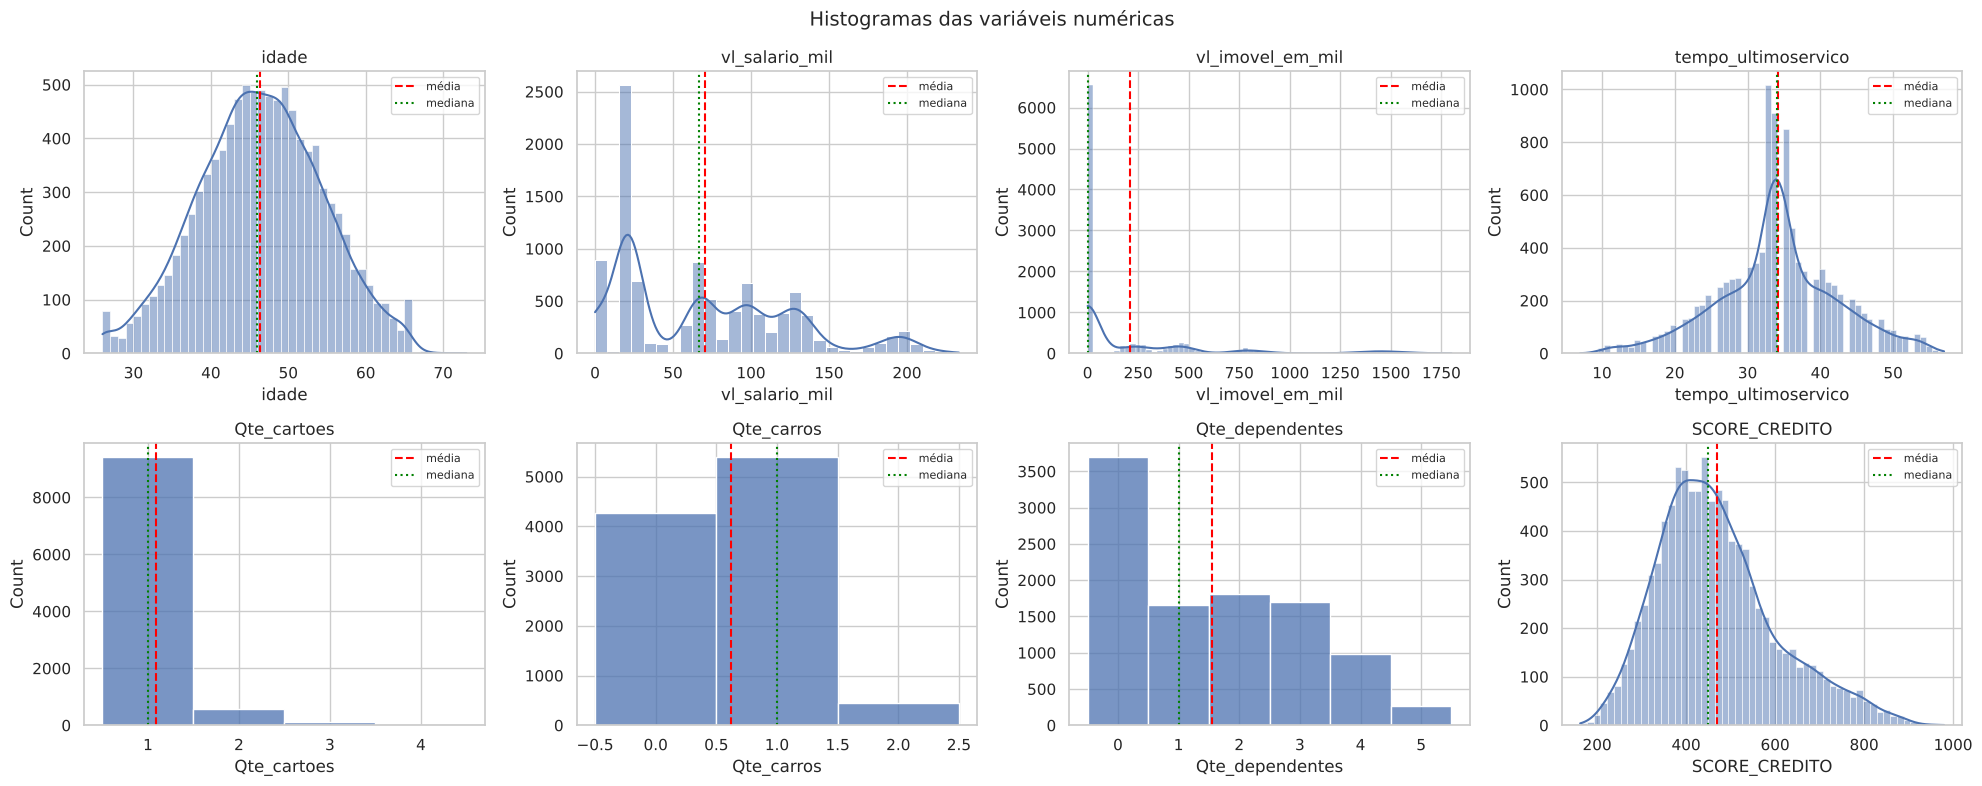

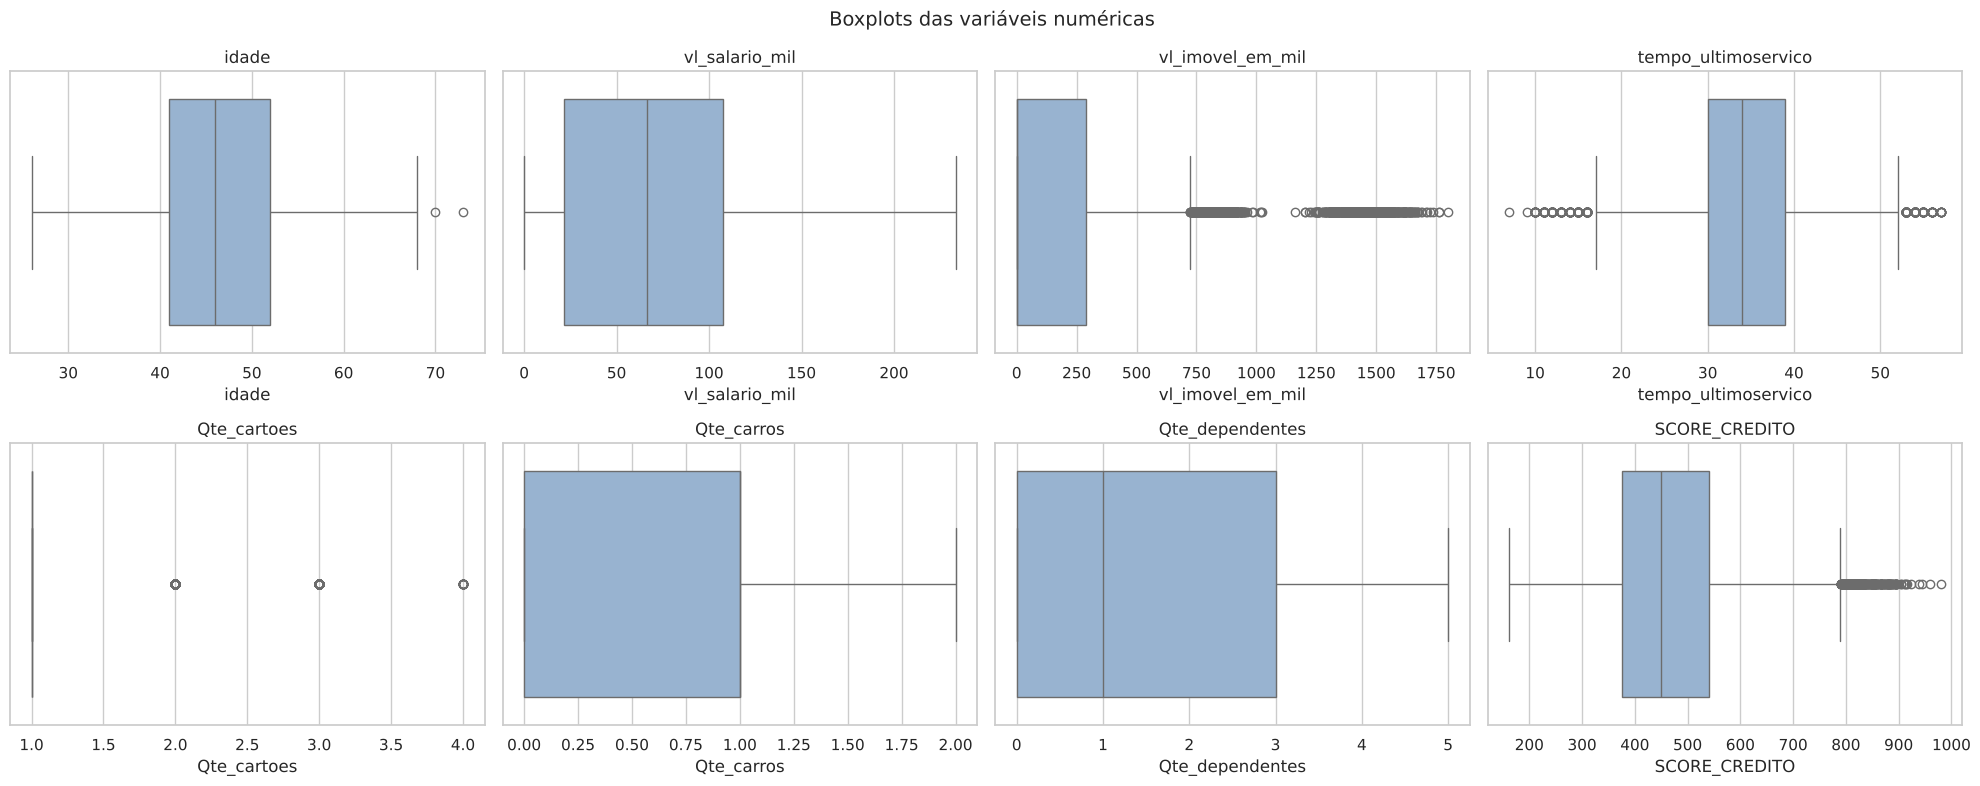

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.flat, desc_cols):
    discreta = df[c].nunique() <= 10
    sns.histplot(df[c], kde=not discreta, discrete=discreta, ax=ax, color="#4c72b0")
    ax.axvline(df[c].mean(), color="red", ls="--", label="média")
    ax.axvline(df[c].median(), color="green", ls=":", label="mediana")
    ax.set_title(c); ax.legend(fontsize=8)
plt.suptitle("Histogramas das variáveis numéricas", fontsize=14); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, c in zip(axes.flat, desc_cols):
    sns.boxplot(x=df[c], ax=ax, color="#8fb3d9"); ax.set_title(c)
plt.suptitle("Boxplots das variáveis numéricas", fontsize=14); plt.tight_layout(); plt.show()

**Leitura:**
- **Score**: média ≈ 470 e mediana ≈ 450, com assimetria à direita (cauda de clientes com score alto).
- **Salário** e **valor do imóvel** têm muitos zeros (não trabalha / não tem casa) e grande dispersão (coeficientes de variação altos).
- **Idade** e **tempo de serviço** são aproximadamente simétricos. Cartões, carros e dependentes são contagens com poucos valores distintos.

### 4.2 Variáveis categóricas — tabelas de frequência

In [11]:
for c in cat_cols + bin_cols:
    ordem = CATEGORIAS.get(c, sorted(df[c].unique()))
    tab = pd.DataFrame({"frequência": df[c].value_counts(), "%": df[c].value_counts(normalize=True) * 100,
                        "score_médio": df.groupby(c)[TARGET].mean(),
                        "score_mediano": df.groupby(c)[TARGET].median()}).loc[ordem]
    tab.loc["Total"] = [tab["frequência"].sum(), 100, df[TARGET].mean(), df[TARGET].median()]
    print(f"\n=== {c} ==="); display(tab)


=== sexo ===


,frequência,%,score_médio,score_mediano
sexo,,,,
F,"5,358.0000",52.9081,442.0073,429.3000
M,"4,769.0000",47.0919,500.3890,480.6000
Total,"10,127.0000",100.0000,469.5004,449.6000



=== estado_civil ===


,frequência,%,score_médio,score_mediano
estado_civil,,,,
casado,"4,687.0000",46.2822,476.3361,455.0000
divorciado,748.0000,7.3862,494.7759,475.0000
na,749.0000,7.3961,500.2040,481.0000
solteiro,"3,943.0000",38.9355,450.7475,434.7000
Total,"10,127.0000",100.0000,469.5004,449.6000



=== escola ===


,frequência,%,score_médio,score_mediano
escola,,,,
ensino fundam,"2,283.0000",22.5437,429.6017,417.0000
ensino medio,"3,352.0000",33.0996,477.5879,459.0000
graduacao,"2,094.0000",20.6774,471.9917,451.4400
mestrado,"1,639.0000",16.1845,486.5586,468.9000
doutorado,759.0000,7.4948,510.0852,488.7000
Total,"10,127.0000",100.0000,469.5004,449.6000


... (2 outputs left out)


=== trabalha ===


,frequência,%,score_médio,score_mediano
trabalha,,,,
0,892.0000,8.8081,368.5026,370.2400
1,"9,235.0000",91.1919,479.2556,460.8000
Total,"10,127.0000",100.0000,469.5004,449.6000



=== casa_propria ===


,frequência,%,score_médio,score_mediano
casa_propria,,,,
0,"6,558.0000",64.7576,444.8604,434.7000
1,"3,569.0000",35.2424,514.7761,491.0000
Total,"10,127.0000",100.0000,469.5004,449.6000


### 4.3 Boxplots do score por categoria

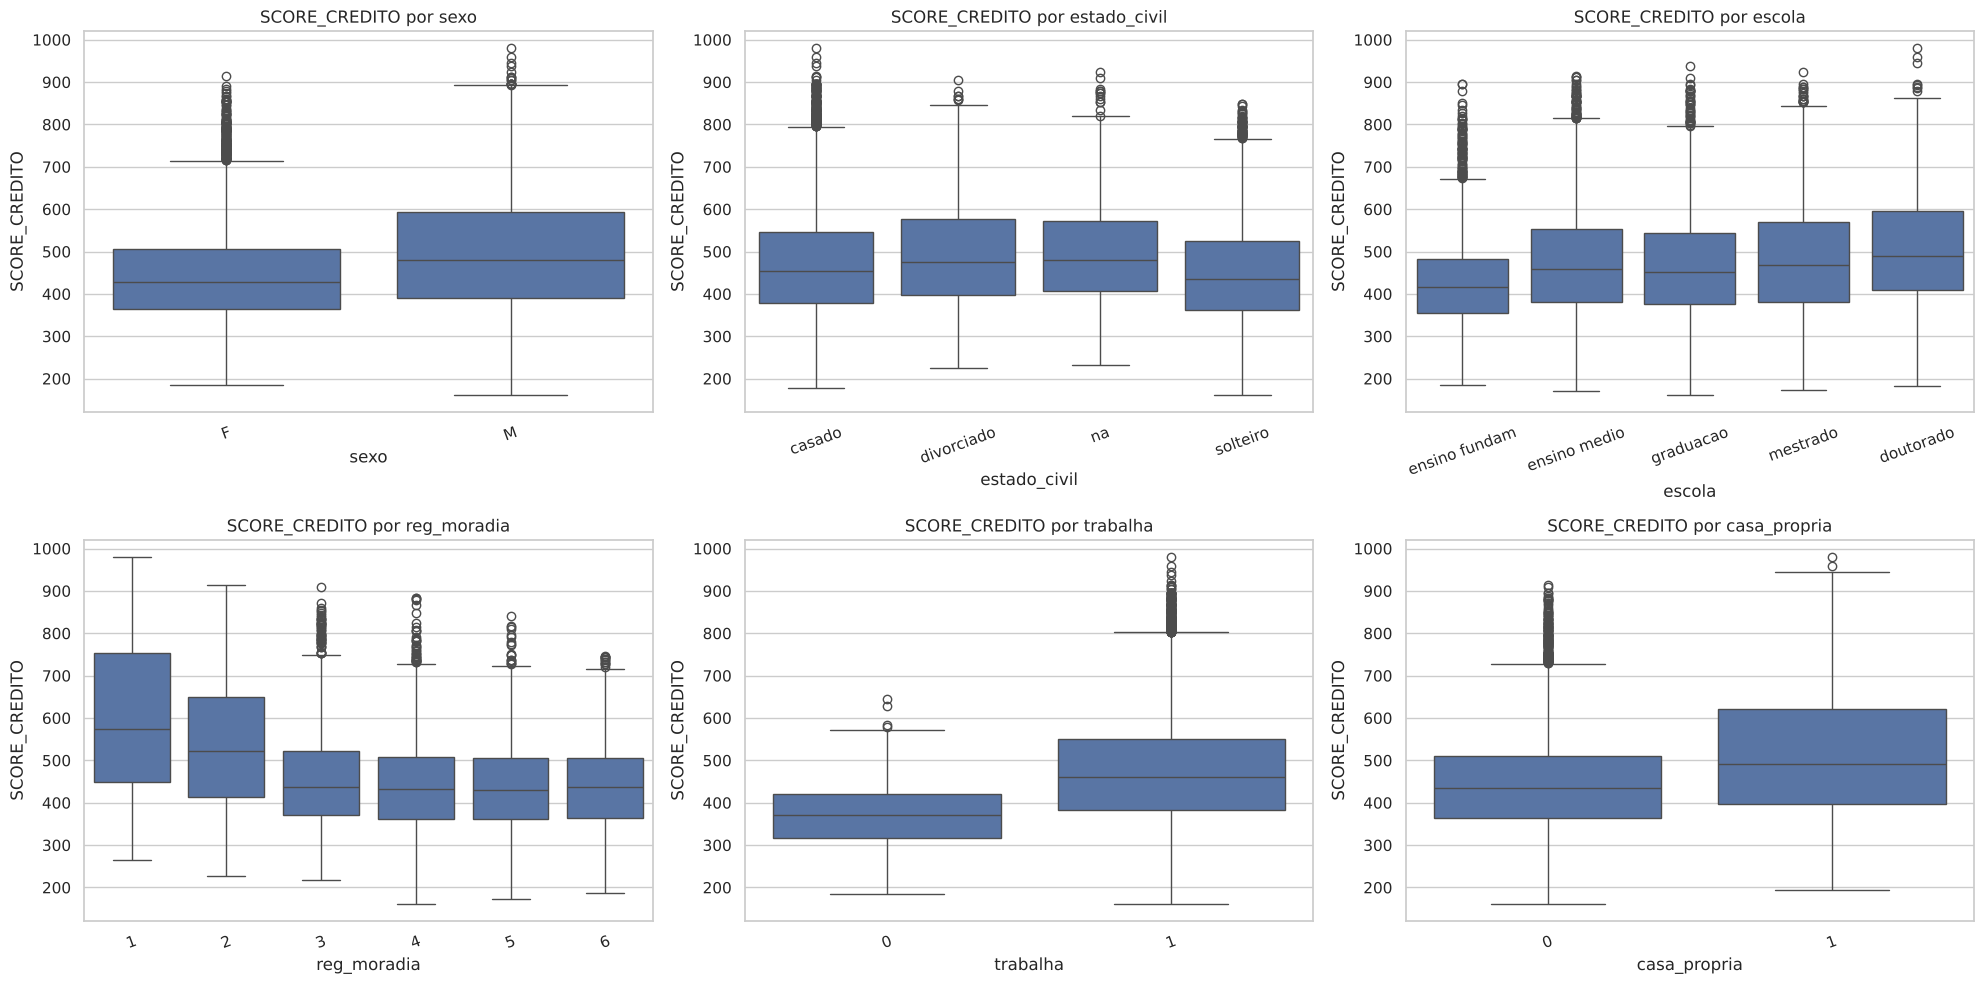

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for ax, c in zip(axes.flat, cat_cols + bin_cols):
    sns.boxplot(data=df, x=c, y=TARGET, order=CATEGORIAS.get(c, sorted(df[c].unique())), ax=ax)
    ax.set_title(f"SCORE_CREDITO por {c}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [13]:
# A diferença de score entre as categorias é estatisticamente significativa? (t de Welch / ANOVA)
res = []
for c in cat_cols + bin_cols:
    grupos = [g[TARGET].values for _, g in df.groupby(c)]
    if len(grupos) == 2:
        st, p = stats.ttest_ind(*grupos, equal_var=False); teste = "t de Welch"
    else:
        st, p = stats.f_oneway(*grupos); teste = "ANOVA"
    res.append([c, teste, st, p, "Sim" if p < .05 else "Não"])
pd.DataFrame(res, columns=["variável", "teste", "estatística", "p_valor", "diferença significativa (5%)"])

,variável,teste,estatística,p_valor,diferença significativa (5%)
0,sexo,t de Welch,-22.1720,0.0000,Sim
1,estado_civil,ANOVA,52.7251,0.0000,Sim
2,escola,ANOVA,80.5498,0.0000,Sim
3,reg_moradia,ANOVA,336.1769,0.0000,Sim
4,trabalha,t de Welch,-37.0643,0.0000,Sim
5,casa_propria,t de Welch,-24.0002,0.0000,Sim


## 5. Análise de correlação

### 5.1 Matriz de correlação (Pearson)

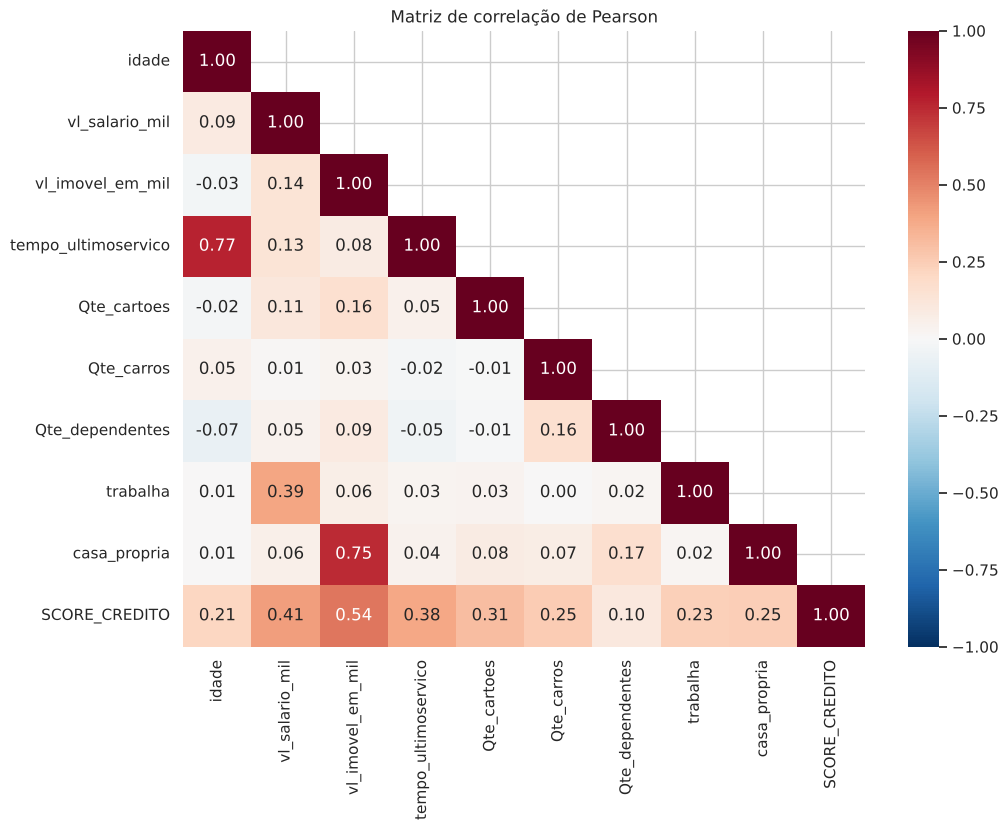

In [14]:
corr = df[num_cols + bin_cols + [TARGET]].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1))
plt.title("Matriz de correlação de Pearson"); plt.show()

### 5.2 Variáveis mais relacionadas com o `SCORE_CREDITO`

,variável,pearson,spearman,p_valor,intensidade
0,vl_imovel_em_mil,0.5373,0.3158,0.0000,forte
1,vl_salario_mil,0.4141,0.4618,0.0000,moderada
2,tempo_ultimoservico,0.3840,0.3733,0.0000,moderada
3,Qte_cartoes,0.3105,0.2758,0.0000,moderada
4,Qte_carros,0.2530,0.2624,0.0000,fraca
5,casa_propria,0.2496,0.2165,0.0000,fraca
6,trabalha,0.2346,0.2504,0.0000,fraca
7,idade,0.2133,0.2442,0.0000,fraca
8,Qte_dependentes,0.1036,0.1015,0.0000,fraca


,correlação com o score
reg_moradia_2,0.1655
reg_moradia_3,-0.0630
reg_moradia_4,-0.1036
reg_moradia_5,-0.1074
reg_moradia_6,-0.1047


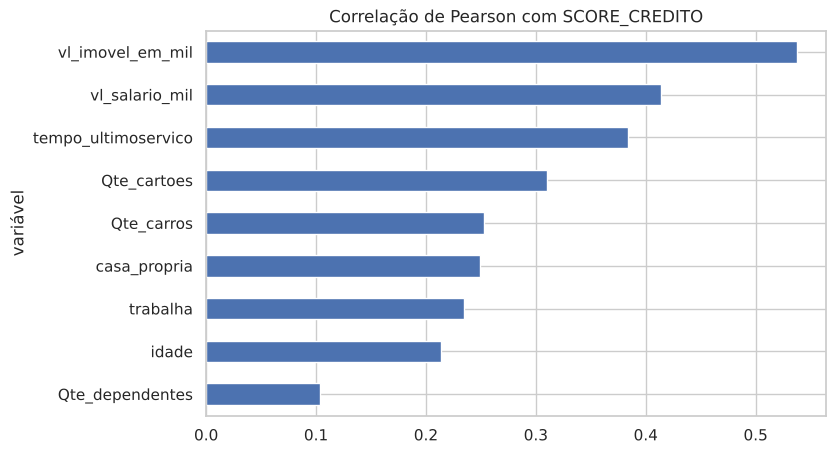

In [15]:
linhas = []
for c in num_cols + bin_cols:
    r, p = stats.pearsonr(df[c], df[TARGET])
    rho, _ = stats.spearmanr(df[c], df[TARGET])
    linhas.append([c, r, rho, p])
corr_t = (pd.DataFrame(linhas, columns=["variável", "pearson", "spearman", "p_valor"])
            .assign(abs_r=lambda d: d.pearson.abs()).sort_values("abs_r", ascending=False).drop(columns="abs_r"))
corr_t["intensidade"] = pd.cut(corr_t.pearson.abs(), [0, .1, .3, .5, 1], labels=["muito fraca", "fraca", "moderada", "forte"])
display(corr_t.reset_index(drop=True))

# Região de moradia é categórica: usamos a correlação de cada dummy com o score
corr_reg = X.filter(like="reg_moradia_").corrwith(y).to_frame("correlação com o score")
display(corr_reg)

corr_t.set_index("variável")["pearson"].sort_values().plot.barh(figsize=(8, 5), color="#4c72b0")
plt.title("Correlação de Pearson com SCORE_CREDITO"); plt.show()

### 5.3 Pares muito correlacionados entre si (risco de multicolinearidade)

In [16]:
pares = (corr.drop(index=TARGET, columns=TARGET).where(np.triu(np.ones((len(corr) - 1,) * 2, dtype=bool), k=1))
             .stack().rename("r").reset_index().rename(columns={"level_0": "var_1", "level_1": "var_2"}))
pares = pares.reindex(pares.r.abs().sort_values(ascending=False).index).head(8).reset_index(drop=True)
pares["risco"] = np.where(pares.r.abs() >= .7, "alto", np.where(pares.r.abs() >= .4, "moderado", "baixo"))
pares

,var_1,var_2,r,risco
0,idade,tempo_ultimoservico,0.7688,alto
1,vl_imovel_em_mil,casa_propria,0.7485,alto
2,vl_salario_mil,trabalha,0.3927,baixo
3,Qte_dependentes,casa_propria,0.1670,baixo
4,Qte_carros,Qte_dependentes,0.1640,baixo
5,vl_imovel_em_mil,Qte_cartoes,0.1625,baixo
6,vl_salario_mil,vl_imovel_em_mil,0.1359,baixo
7,vl_salario_mil,tempo_ultimoservico,0.1341,baixo


**Anotações da correlação**
- Maiores correlações com o score: **valor do imóvel**, **salário** e **tempo do último serviço** (positivas), seguidos de cartões, região de moradia, casa própria, carros e trabalha.
- `Qte_dependentes` e `idade` têm as relações mais fracas. `reg_moradia` (categórica) mostra score maior nas regiões 1 e 2 e menor nas regiões 4, 5 e 6.
- **Risco de multicolinearidade** (pares com |r| alto):
  - **`idade` × `tempo_ultimoservico` (r ≈ 0,77)** — quem é mais velho tende a ter mais tempo de serviço;
  - **`casa_propria` × `vl_imovel_em_mil` (r ≈ 0,75)** — o valor do imóvel só existe para quem tem casa;
  - `trabalha` × `vl_salario_mil` (r ≈ 0,39) — salário é zero para quem não trabalha.
- Ao contrário do que se poderia esperar, **salário × valor do imóvel** tem correlação **fraca (r ≈ 0,14)** nesta base, então não é uma fonte relevante de multicolinearidade.
- Esses pares são acompanhados pelo VIF na etapa 7.

## 6. Modelo de regressão linear múltipla

### 6.1 Separação treino / teste (70% / 30%)
O modelo é estimado só no treino; o teste fica guardado para medir o erro em clientes “novos”.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=SEED)
print(f"Treino: {X_train.shape[0]:,} clientes | Teste: {X_test.shape[0]:,} clientes")
print(f"Score médio — treino: {y_train.mean():.1f} | teste: {y_test.mean():.1f}")

Treino: 7,088 clientes | Teste: 3,039 clientes
Score médio — treino: 469.4 | teste: 469.7


### 6.2 Modelo completo (todas as variáveis)

In [18]:
modelo_full = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(modelo_full.summary())

                            OLS Regression Results                            
Dep. Variable:          SCORE_CREDITO   R-squared:                       0.676
Model:                            OLS   Adj. R-squared:                  0.675
Method:                 Least Squares   F-statistic:                     670.4
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:20:31   Log-Likelihood:                -40766.
No. Observations:                7088   AIC:                         8.158e+04
Df Residuals:                    7065   BIC:                         8.174e+04
Df Model:                          22                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [19]:
pv = modelo_full.pvalues.drop("const")
print("Variáveis NÃO significativas a 5% no modelo completo:")
display(pv[pv > .05].sort_values(ascending=False).to_frame("p_valor"))

Variáveis NÃO significativas a 5% no modelo completo:


,p_valor
reg_moradia_2,0.8288
reg_moradia_3,0.1965
estado_civil_solteiro,0.0820


### 6.3 Seleção de variáveis — *stepwise backward*
A cada passo é retirada a variável com **maior p-valor acima de 5%** e o modelo é reestimado, até todas serem significativas.

In [20]:
def backward_elimination(X, y, alpha=0.05):
    cols, passos = list(X.columns), []
    while True:
        m = sm.OLS(y, sm.add_constant(X[cols])).fit()
        pvals = m.pvalues.drop("const")
        pior = pvals.idxmax()
        if pvals[pior] <= alpha:
            return m, cols, pd.DataFrame(passos, columns=["passo", "variável retirada", "p_valor", "R²_ajustado_antes"])
        passos.append([len(passos) + 1, pior, pvals[pior], m.rsquared_adj])
        cols.remove(pior)

modelo, vars_modelo, passos = backward_elimination(X_train, y_train)
display(passos)
print(f"Variáveis mantidas ({len(vars_modelo)}):", vars_modelo)

,passo,variável retirada,p_valor,R²_ajustado_antes
0,1,reg_moradia_2,0.8288,0.6751
1,2,reg_moradia_3,0.1596,0.6752
2,3,estado_civil_solteiro,0.1322,0.6751


Variáveis mantidas (19): ['idade', 'vl_salario_mil', 'vl_imovel_em_mil', 'tempo_ultimoservico', 'Qte_cartoes', 'Qte_carros', 'Qte_dependentes', 'trabalha', 'casa_propria', 'sexo_M', 'estado_civil_divorciado', 'estado_civil_na', 'escola_ensino medio', 'escola_graduacao', 'escola_mestrado', 'escola_doutorado', 'reg_moradia_4', 'reg_moradia_5', 'reg_moradia_6']


In [21]:
print(modelo.summary())

                            OLS Regression Results                            
Dep. Variable:          SCORE_CREDITO   R-squared:                       0.676
Model:                            OLS   Adj. R-squared:                  0.675
Method:                 Least Squares   F-statistic:                     775.9
Date:                Tue, 20 Oct 2026   Prob (F-statistic):               0.00
Time:                        22:20:31   Log-Likelihood:                -40768.
No. Observations:                7088   AIC:                         8.158e+04
Df Residuals:                    7068   BIC:                         8.171e+04
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                              coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------
const                     

In [22]:
comparacao = pd.DataFrame({
    "Modelo completo": [len(modelo_full.params) - 1, modelo_full.rsquared, modelo_full.rsquared_adj, modelo_full.aic, modelo_full.bic],
    "Modelo stepwise": [len(modelo.params) - 1, modelo.rsquared, modelo.rsquared_adj, modelo.aic, modelo.bic],
}, index=["nº variáveis", "R²", "R² ajustado", "AIC", "BIC"])
comparacao

,Modelo completo,Modelo stepwise
nº variáveis,22.0000,19.0000
R²,0.6761,0.6759
R² ajustado,0.6751,0.6751
AIC,"81,578.0384","81,576.3435"
BIC,"81,735.9600","81,713.6666"


O modelo *stepwise* tem menos variáveis praticamente com o mesmo R² ajustado e AIC/BIC menores — é mais simples sem perder poder explicativo.

### 6.4 Equação e interpretação dos coeficientes

In [23]:
coefs = pd.DataFrame({"coef": modelo.params, "erro_padrão": modelo.bse, "t": modelo.tvalues, "p_valor": modelo.pvalues,
                      "IC95_inf": modelo.conf_int()[0], "IC95_sup": modelo.conf_int()[1]})
display(coefs)

termos = "\n   ".join(f"{'+' if b >= 0 else '-'} {abs(b):.4f} × {v}" for v, b in modelo.params.drop("const").items())
print(f"SCORE_CREDITO = {modelo.params['const']:.4f}\n   {termos}")

,coef,erro_padrão,t,p_valor,IC95_inf,IC95_sup
const,128.6447,7.6656,16.7820,0.0000,113.6178,143.6716
idade,-1.2638,0.1829,-6.9106,0.0000,-1.6224,-0.9053
vl_salario_mil,0.6884,0.0266,25.9232,0.0000,0.6364,0.7405
vl_imovel_em_mil,0.2340,0.0038,62.3539,0.0000,0.2267,0.2414
tempo_ultimoservico,5.7958,0.1772,32.7154,0.0000,5.4485,6.1431
Qte_cartoes,69.8287,2.7324,25.5558,0.0000,64.4724,75.1850
Qte_carros,60.0569,1.6271,36.9106,0.0000,56.8673,63.2465
Qte_dependentes,5.6160,0.6587,8.5257,0.0000,4.3247,6.9072
trabalha,41.0065,3.4724,11.8093,0.0000,34.1995,47.8134
casa_propria,-120.2050,4.1183,-29.1877,0.0000,-128.2782,-112.1318


SCORE_CREDITO = 128.6447
   - 1.2638 × idade
   + 0.6884 × vl_salario_mil
   + 0.2340 × vl_imovel_em_mil
   + 5.7958 × tempo_ultimoservico
   + 69.8287 × Qte_cartoes
   + 60.0569 × Qte_carros
   + 5.6160 × Qte_dependentes
   + 41.0065 × trabalha
   - 120.2050 × casa_propria
   - 17.4378 × sexo_M
   + 22.6052 × estado_civil_divorciado
   + 17.8105 × estado_civil_na
   + 12.4107 × escola_ensino medio
   + 13.4126 × escola_graduacao
   + 20.0284 × escola_mestrado
   + 11.7760 × escola_doutorado
   - 31.1446 × reg_moradia_4
   - 33.5843 × reg_moradia_5
   - 37.1282 × reg_moradia_6


In [24]:
UNIDADE = {"idade": "ano a mais de idade", "vl_salario_mil": "mil reais a mais de salário",
           "vl_imovel_em_mil": "mil reais a mais no valor do imóvel", "tempo_ultimoservico": "unidade a mais de tempo no último serviço",
           "Qte_cartoes": "cartão a mais", "Qte_carros": "carro a mais", "Qte_dependentes": "dependente a mais"}
BINARIA = {"trabalha": "trabalhar (vs. não trabalhar)", "casa_propria": "ter casa própria (vs. não ter)"}

def interpretar(var, b):
    efeito = f"{'aumenta' if b > 0 else 'reduz'} o score em {abs(b):.2f} pontos"
    if var in UNIDADE:
        return f"Cada {UNIDADE[var]} {efeito}"
    if var in BINARIA:
        return f"{BINARIA[var].capitalize()} {efeito}"
    col, cat = next((c, var[len(c) + 1:]) for c in cat_cols if var.startswith(c + "_"))
    return f"{col} = '{cat}' (vs. '{REFERENCIA[col]}') {efeito}"

print("Mantidas as demais variáveis constantes:\n")
for v, b in modelo.params.drop("const").items():
    print(" •", interpretar(v, b))

Mantidas as demais variáveis constantes:



 • Cada ano a mais de idade reduz o score em 1.26 pontos
 • Cada mil reais a mais de salário aumenta o score em 0.69 pontos
 • Cada mil reais a mais no valor do imóvel aumenta o score em 0.23 pontos
 • Cada unidade a mais de tempo no último serviço aumenta o score em 5.80 pontos
 • Cada cartão a mais aumenta o score em 69.83 pontos
 • Cada carro a mais aumenta o score em 60.06 pontos
 • Cada dependente a mais aumenta o score em 5.62 pontos
 • Trabalhar (vs. não trabalhar) aumenta o score em 41.01 pontos
 • Ter casa própria (vs. não ter) reduz o score em 120.20 pontos
 • sexo = 'M' (vs. 'F') reduz o score em 17.44 pontos
 • estado_civil = 'divorciado' (vs. 'casado') aumenta o score em 22.61 pontos
 • estado_civil = 'na' (vs. 'casado') aumenta o score em 17.81 pontos
 • escola = 'ensino medio' (vs. 'ensino fundam') aumenta o score em 12.41 pontos
 • escola = 'graduacao' (vs. 'ensino fundam') aumenta o score em 13.41 pontos
 • escola = 'mestrado' (vs. 'ensino fundam') aumenta o score em 

**Atenção ao interpretar `casa_propria` e `vl_imovel_em_mil` juntos:** o coeficiente negativo de `casa_propria` (≈ −120) não significa que ter casa piora o score.
Ele funciona como um “ajuste de intercepto” para quem tem imóvel, que é compensado pelo valor do imóvel (+0,23 por mil reais).
O efeito líquido de ter casa é `−120 + 0,234 × valor_do_imóvel`, que se torna positivo a partir de ≈ R$ 514 mil — ou seja, **o que pesa no score é o valor do patrimônio**, não apenas possuir casa.

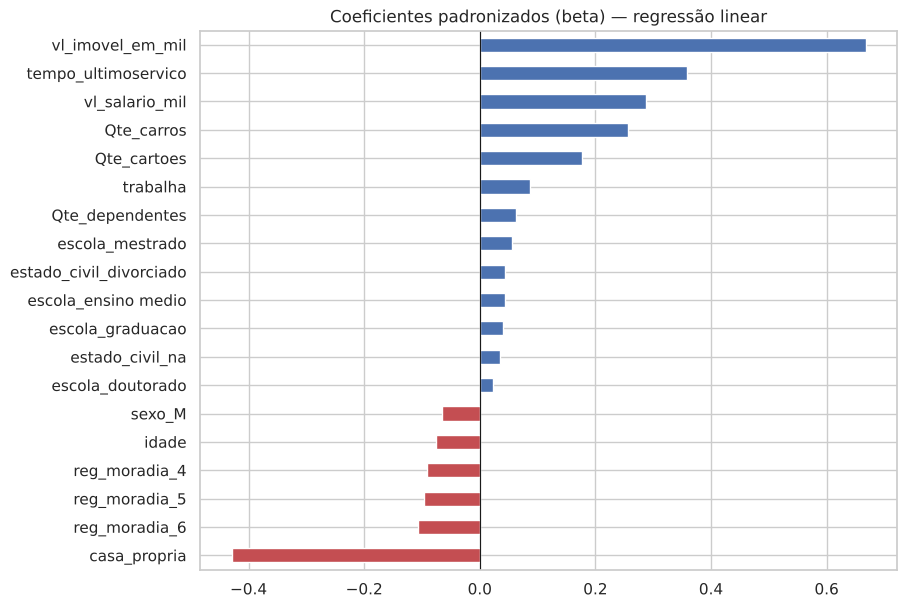

In [25]:
# Coeficientes padronizados (beta): permitem comparar a importância relativa entre variáveis de escalas diferentes
beta = (modelo.params.drop("const") * X_train[vars_modelo].std() / y_train.std()).sort_values()
beta.plot.barh(figsize=(9, 7), color=np.where(beta > 0, "#4c72b0", "#c44e52"))
plt.title("Coeficientes padronizados (beta) — regressão linear"); plt.axvline(0, color="k", lw=.8); plt.show()

## 7. Verificação das suposições da regressão

| Suposição | Diagnóstico gráfico | Teste formal | Regra de decisão |
|---|---|---|---|
| Normalidade dos resíduos | Histograma, QQ-plot | Shapiro-Wilk (e Jarque-Bera) | p > 0,05 → normal |
| Homocedasticidade | Resíduo × previsto | Breusch-Pagan | p > 0,05 → variância constante |
| Independência | Resíduos na ordem das observações | Durbin-Watson | DW ≈ 2 (entre 1,5 e 2,5) |
| Multicolinearidade | — | VIF | VIF > 5 moderado, > 10 grave |

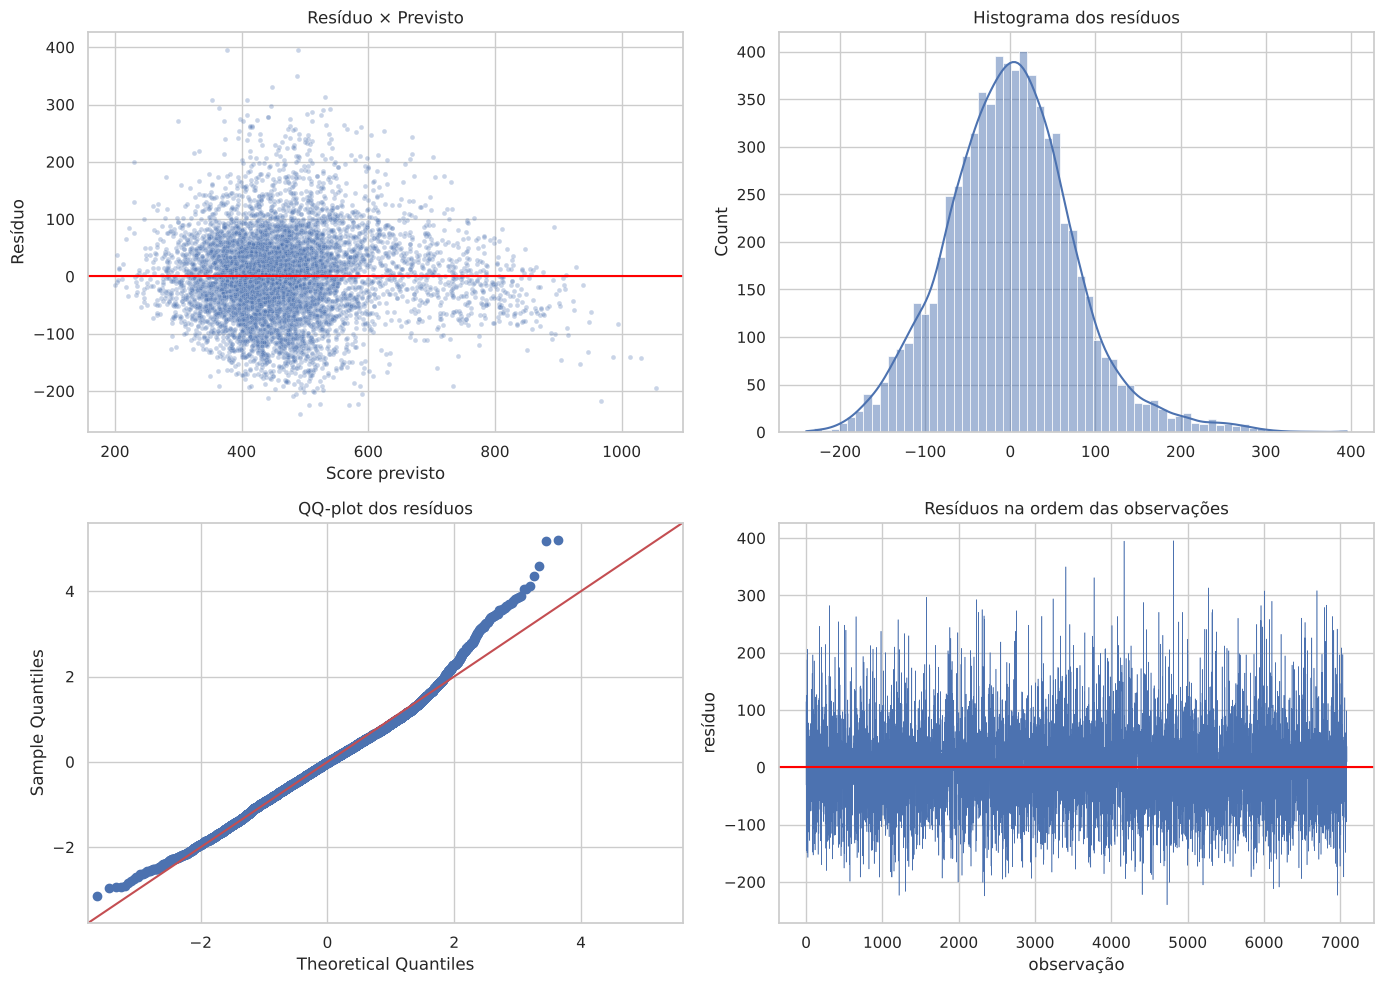

In [26]:
residuos, ajustados = modelo.resid, modelo.fittedvalues

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.scatterplot(x=ajustados, y=residuos, alpha=.3, s=12, ax=axes[0, 0])
axes[0, 0].axhline(0, color="red"); axes[0, 0].set(title="Resíduo × Previsto", xlabel="Score previsto", ylabel="Resíduo")
sns.histplot(residuos, kde=True, ax=axes[0, 1]); axes[0, 1].set_title("Histograma dos resíduos")
sm.qqplot(residuos, line="45", fit=True, ax=axes[1, 0]); axes[1, 0].set_title("QQ-plot dos resíduos")
axes[1, 1].plot(residuos.values, lw=.4); axes[1, 1].axhline(0, color="red")
axes[1, 1].set(title="Resíduos na ordem das observações", xlabel="observação", ylabel="resíduo")
plt.tight_layout(); plt.show()

In [27]:
# Shapiro-Wilk aceita no máximo 5.000 observações: usamos uma amostra aleatória dos resíduos de treino
amostra_res = residuos.sample(5000, random_state=SEED)
sw, sw_p = stats.shapiro(amostra_res)
jb, jb_p, assim, curt = jarque_bera(residuos)
bp_lm, bp_p, _, _ = het_breuschpagan(residuos, modelo.model.exog)
dw = durbin_watson(residuos)

testes = pd.DataFrame([
    ["Normalidade", "Shapiro-Wilk (n=5.000)", sw, sw_p, "Normal" if sw_p > .05 else "NÃO normal"],
    ["Normalidade", "Jarque-Bera", jb, jb_p, "Normal" if jb_p > .05 else "NÃO normal"],
    ["Homocedasticidade", "Breusch-Pagan", bp_lm, bp_p, "Homocedástico" if bp_p > .05 else "Heterocedástico"],
    ["Independência", "Durbin-Watson", dw, np.nan, "Independentes" if 1.5 < dw < 2.5 else "Autocorrelação"],
], columns=["suposição", "teste", "estatística", "p_valor", "conclusão"])
display(testes)
print(f"Assimetria dos resíduos: {assim:.3f} | Curtose: {curt:.3f} (normal = 3)")

,suposição,teste,estatística,p_valor,conclusão
0,Normalidade,Shapiro-Wilk (n=5.000),0.9877,0.0000,NÃO normal
1,Normalidade,Jarque-Bera,497.6705,0.0000,NÃO normal
2,Homocedasticidade,Breusch-Pagan,559.5298,0.0000,Heterocedástico
3,Independência,Durbin-Watson,1.9660,NaN,Independentes


Assimetria dos resíduos: 0.391 | Curtose: 4.036 (normal = 3)


In [28]:
X_vif = sm.add_constant(X_train[vars_modelo])
vif = pd.DataFrame({"variável": vars_modelo,
                    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(vars_modelo))]})
vif["diagnóstico"] = np.select([vif.VIF > 10, vif.VIF > 5], ["grave (>10)", "moderado (>5)"], "ok")
vif.sort_values("VIF", ascending=False).reset_index(drop=True)

,variável,VIF,diagnóstico
0,casa_propria,4.7225,ok
1,vl_salario_mil,2.6739,ok
2,idade,2.6217,ok
3,tempo_ultimoservico,2.6104,ok
4,reg_moradia_6,2.5333,ok
5,reg_moradia_5,2.5325,ok
6,reg_moradia_4,2.5324,ok
7,vl_imovel_em_mil,2.4988,ok
8,sexo_M,2.2240,ok
9,escola_ensino medio,1.6693,ok


In [29]:
# Pontos influentes (distância de Cook)
cooks = modelo.get_influence().cooks_distance[0]
limite = 4 / len(cooks)
print(f"Observações com Cook > 4/n ({limite:.5f}): {(cooks > limite).sum()} ({100 * (cooks > limite).mean():.2f}%) | "
      f"máximo = {cooks.max():.4f} (nenhuma > 1 → nenhum ponto isolado domina o modelo)")

Observações com Cook > 4/n (0.00056): 362 (5.11%) | máximo = 0.0064 (nenhuma > 1 → nenhum ponto isolado domina o modelo)


In [30]:
# Robustez: erros-padrão robustos à heterocedasticidade (HC3). A significância se mantém?
modelo_hc3 = sm.OLS(y_train, X_vif).fit(cov_type="HC3")
rob = pd.DataFrame({"coef": modelo.params, "p_valor_MQO": modelo.pvalues, "p_valor_HC3": modelo_hc3.pvalues})
rob["significativa_HC3"] = np.where(rob.p_valor_HC3 < .05, "Sim", "Não")
rob

,coef,p_valor_MQO,p_valor_HC3,significativa_HC3
const,128.6447,0.0000,0.0000,Sim
idade,-1.2638,0.0000,0.0000,Sim
vl_salario_mil,0.6884,0.0000,0.0000,Sim
vl_imovel_em_mil,0.2340,0.0000,0.0000,Sim
tempo_ultimoservico,5.7958,0.0000,0.0000,Sim
Qte_cartoes,69.8287,0.0000,0.0000,Sim
Qte_carros,60.0569,0.0000,0.0000,Sim
Qte_dependentes,5.6160,0.0000,0.0000,Sim
trabalha,41.0065,0.0000,0.0000,Sim
casa_propria,-120.2050,0.0000,0.0000,Sim


**Conclusão das suposições**

| Suposição | Resultado | Atendida? |
|---|---|---|
| Normalidade | Shapiro-Wilk e Jarque-Bera rejeitam H0 (p < 0,001); o QQ-plot mostra caudas um pouco mais pesadas, em especial à direita (assimetria ≈ 0,39, curtose ≈ 4) | **Parcialmente** — desvio moderado; com n > 7.000 os testes rejeitam até desvios pequenos e, pelo Teorema Central do Limite, as inferências sobre os coeficientes continuam válidas |
| Homocedasticidade | Breusch-Pagan rejeita H0 (p < 0,001); o gráfico resíduo × previsto mostra dispersão crescente nos scores mais altos | **Não** — corrigido com erros-padrão robustos HC3: **todas as variáveis seguem significativas** |
| Independência | Durbin-Watson ≈ 1,97 | **Sim** |
| Multicolinearidade | Todos os VIF < 5 (maior: `casa_propria` ≈ 4,7) | **Sim** |
| Pontos influentes | Distância de Cook máxima ≈ 0,006 (bem abaixo de 1) | **Sim** — nenhum cliente isolado distorce o modelo |

## 8. Qualidade e erros do modelo (base de teste)

In [31]:
def metricas(y_true, y_pred, k):
    n = len(y_true); r2 = r2_score(y_true, y_pred)
    return {"R²": r2, "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - k - 1),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)), "MAE": mean_absolute_error(y_true, y_pred),
            "MAPE_%": 100 * mean_absolute_percentage_error(y_true, y_pred)}

pred_train_rl = modelo.predict(sm.add_constant(X_train[vars_modelo]))
pred_test_rl = modelo.predict(sm.add_constant(X_test[vars_modelo], has_constant="add"))
k = len(vars_modelo)
met_rl = pd.DataFrame({"Treino": metricas(y_train, pred_train_rl, k), "Teste": metricas(y_test, pred_test_rl, k)})
met_rl

,Treino,Teste
R²,0.6759,0.6274
R² ajustado,0.6751,0.6251
RMSE,76.1556,81.7200
MAE,58.4986,62.0640
MAPE_%,13.5742,14.2216


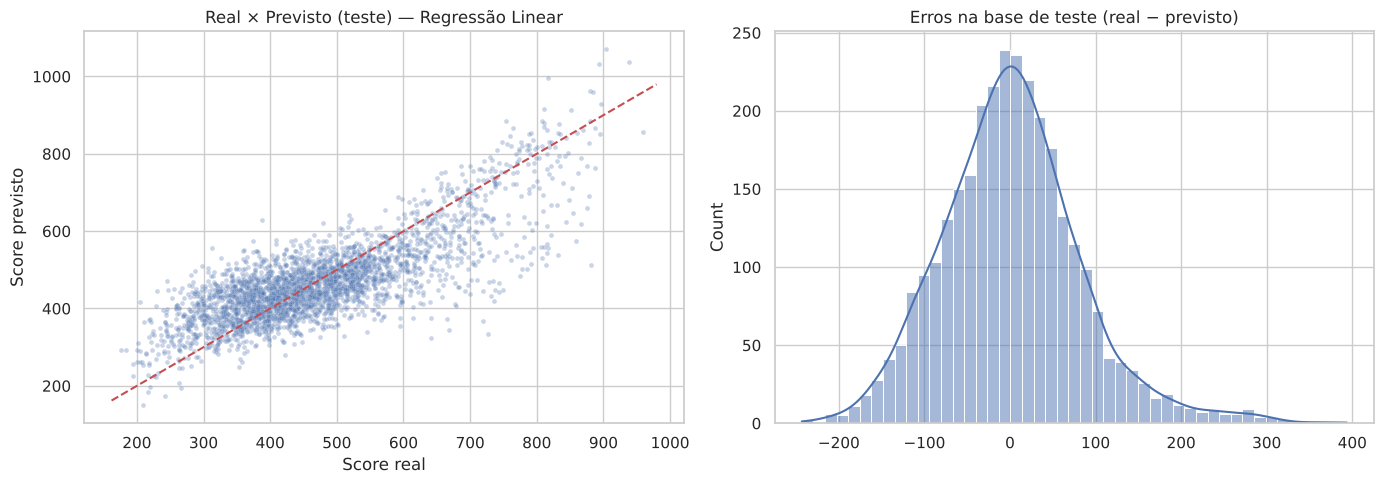

In [32]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
lim = [y.min(), y.max()]
sns.scatterplot(x=y_test, y=pred_test_rl, alpha=.3, s=12, ax=ax[0]); ax[0].plot(lim, lim, "r--")
ax[0].set(title="Real × Previsto (teste) — Regressão Linear", xlabel="Score real", ylabel="Score previsto")
sns.histplot(y_test - pred_test_rl, kde=True, ax=ax[1]); ax[1].set_title("Erros na base de teste (real − previsto)")
plt.tight_layout(); plt.show()

In [33]:
print(f"Interpretação: o modelo explica {met_rl.loc['R²', 'Teste']:.1%} da variação do score em clientes novos;")
print(f"em média erra {met_rl.loc['MAE', 'Teste']:.1f} pontos (MAE), ou {met_rl.loc['MAPE_%', 'Teste']:.1f}% do score (MAPE).")
print(f"RMSE = {met_rl.loc['RMSE', 'Teste']:.1f} pontos (penaliza mais os erros grandes) — o desvio padrão do score é {y.std():.1f}.")

Interpretação: o modelo explica 62.7% da variação do score em clientes novos;
em média erra 62.1 pontos (MAE), ou 14.2% do score (MAPE).
RMSE = 81.7 pontos (penaliza mais os erros grandes) — o desvio padrão do score é 133.8.


## 9. Árvore de decisão (regressão)
Mesmo treino/teste e mesmas variáveis (todas as dummies). Profundidade e tamanho mínimo da folha escolhidos por validação cruzada (5 *folds*) no treino, para evitar *overfitting*.

In [34]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
grid = GridSearchCV(DecisionTreeRegressor(random_state=SEED),
                    {"max_depth": [3, 4, 5, 6, 8, 10, 12], "min_samples_leaf": [5, 10, 20, 50, 100]},
                    cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)
grid.fit(X_train, y_train)
arvore = grid.best_estimator_
print("Melhores hiperparâmetros:", grid.best_params_, f"| nº de folhas: {arvore.get_n_leaves()}")

pred_train_ad, pred_test_ad = arvore.predict(X_train), arvore.predict(X_test)
k_ad = int((arvore.feature_importances_ > 0).sum())
met_ad = pd.DataFrame({"Treino": metricas(y_train, pred_train_ad, k_ad), "Teste": metricas(y_test, pred_test_ad, k_ad)})
met_ad

Melhores hiperparâmetros: {'max_depth': 12, 'min_samples_leaf': 10} | nº de folhas: 350


,Treino,Teste
R²,0.7966,0.6847
R² ajustado,0.7961,0.6828
RMSE,60.3339,75.1765
MAE,45.3311,55.6103
MAPE_%,10.3560,12.5825


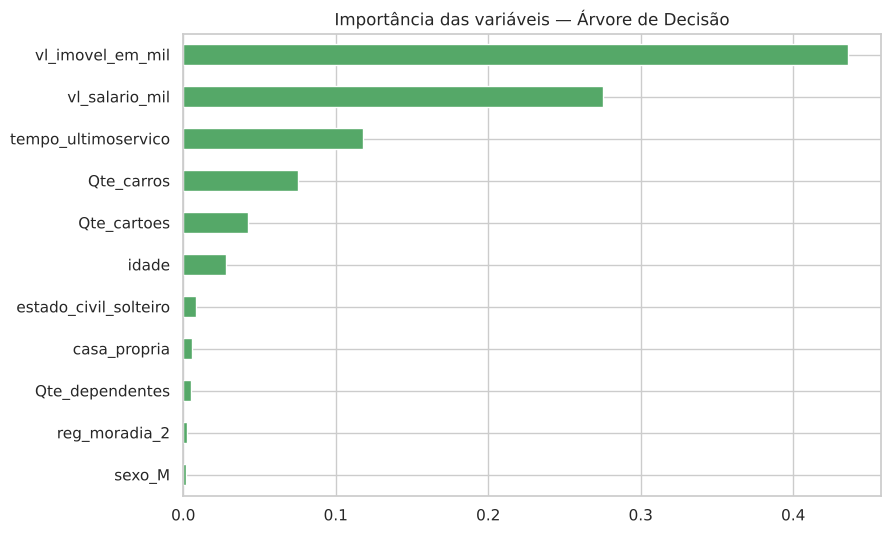

,importância
vl_imovel_em_mil,0.4356
vl_salario_mil,0.2753
tempo_ultimoservico,0.1176
Qte_carros,0.0750
Qte_cartoes,0.0425
idade,0.0280
estado_civil_solteiro,0.0081
casa_propria,0.0056
Qte_dependentes,0.0050
reg_moradia_2,0.0023


In [35]:
imp = pd.Series(arvore.feature_importances_, index=X_train.columns).sort_values()
imp[imp > 0.001].plot.barh(figsize=(9, 6), color="#55a868")
plt.title("Importância das variáveis — Árvore de Decisão"); plt.show()
display(imp.sort_values(ascending=False).head(10).to_frame("importância"))

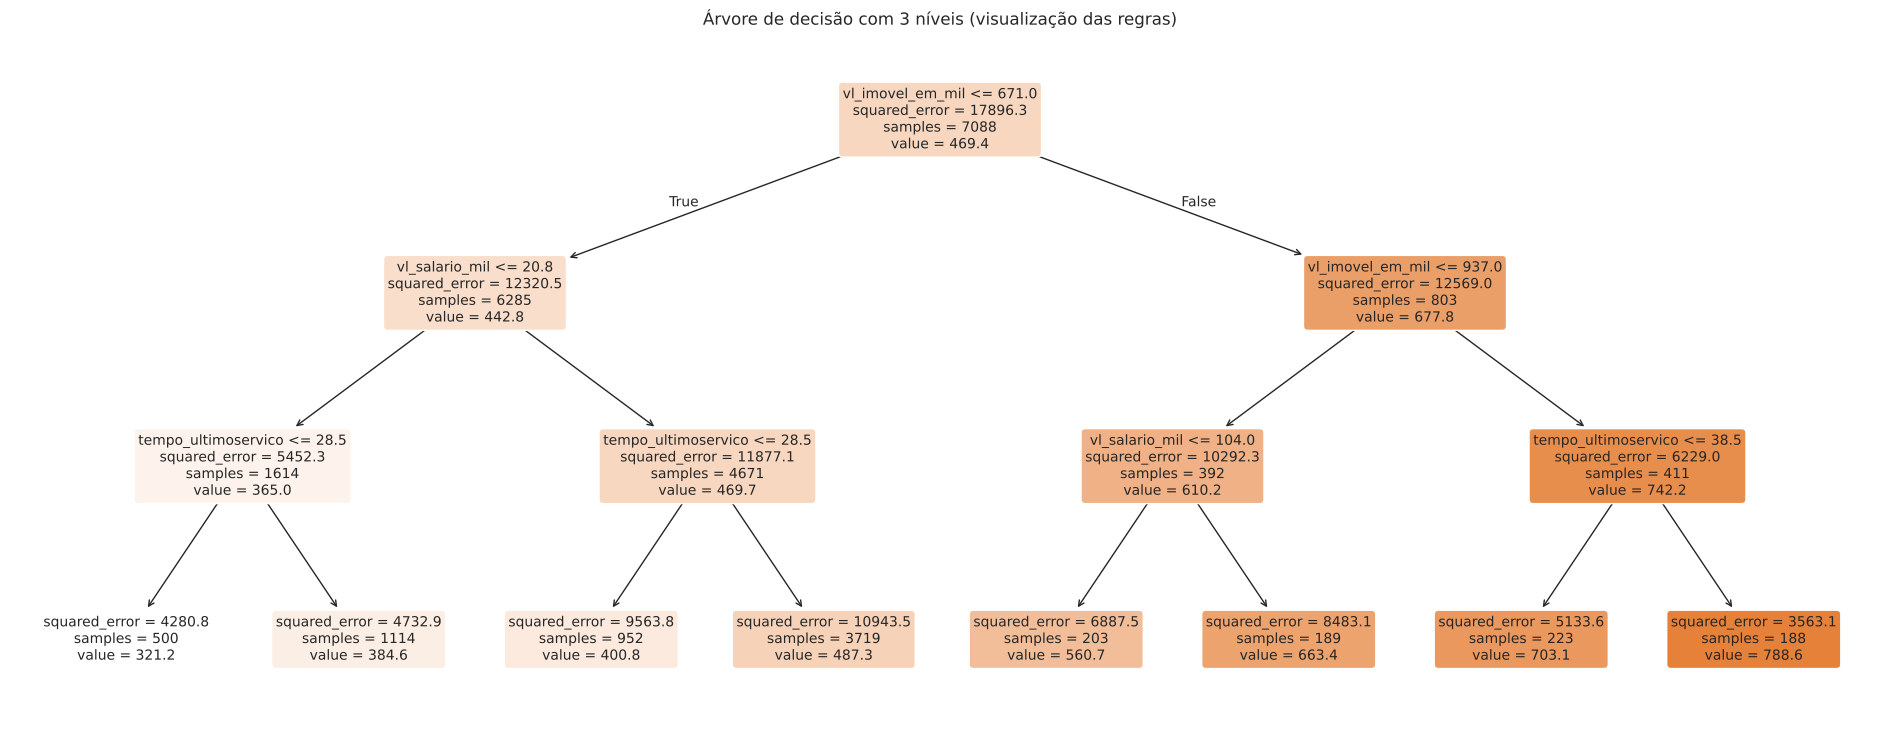

In [36]:
# Árvore rasa (3 níveis) apenas para visualizar as regras que mais separam o score
arvore_viz = DecisionTreeRegressor(max_depth=3, random_state=SEED).fit(X_train, y_train)
plt.figure(figsize=(24, 9))
plot_tree(arvore_viz, feature_names=X_train.columns, filled=True, rounded=True, fontsize=10, precision=1)
plt.title("Árvore de decisão com 3 níveis (visualização das regras)"); plt.show()

### 9.1 Comparação: Regressão Linear × Árvore de Decisão

,Regressão Linear,Árvore de Decisão,melhor
R²,0.6274,0.6847,Árvore de Decisão
R² ajustado,0.6251,0.6828,Árvore de Decisão
RMSE,81.7200,75.1765,Árvore de Decisão
MAE,62.0640,55.6103,Árvore de Decisão
MAPE_%,14.2216,12.5825,Árvore de Decisão


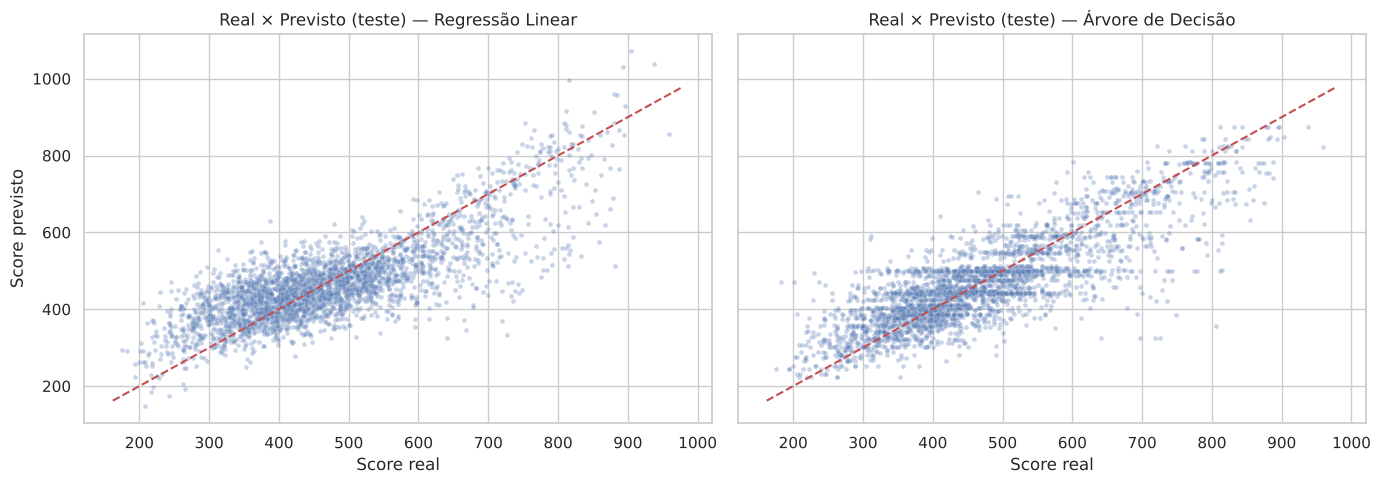

In [37]:
comp = pd.DataFrame({"Regressão Linear": met_rl["Teste"], "Árvore de Decisão": met_ad["Teste"]})
comp["melhor"] = [("Regressão Linear" if (a >= b if m.startswith("R²") else a <= b) else "Árvore de Decisão")
                  for m, a, b in zip(comp.index, comp["Regressão Linear"], comp["Árvore de Decisão"])]
display(comp)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for a, p, t in zip(ax, [pred_test_rl, pred_test_ad], ["Regressão Linear", "Árvore de Decisão"]):
    sns.scatterplot(x=y_test, y=p, alpha=.3, s=12, ax=a); a.plot(lim, lim, "r--")
    a.set(title=f"Real × Previsto (teste) — {t}", xlabel="Score real", ylabel="Score previsto")
plt.tight_layout(); plt.show()

| Critério | Regressão Linear | Árvore de Decisão |
|---|---|---|
| Erro na base de teste | Maior (RMSE ≈ 82, MAE ≈ 62) | **Menor** (RMSE ≈ 75, MAE ≈ 56) |
| Interpretabilidade | Equação única: cada coeficiente diz quantos pontos a variável soma/tira do score | Regras “se… então…”, fáceis de ler em poucos níveis, mas a árvore otimizada tem muitas folhas |
| Previsão | Contínua: qualquer mudança no perfil altera o score | Em degraus: clientes na mesma folha recebem o mesmo score |
| Suposições | Exige normalidade, homocedasticidade, ausência de multicolinearidade | Não exige suposições sobre os resíduos; capta interações e não linearidades |
| Simulador | Implementável numa planilha com uma fórmula | Exige o modelo treinado (Python) |

## 10. Simulador do score

Três formas de uso para analistas de crédito e gerentes de conta, todas com a **mesma equação** da regressão final:
1. **Função Python** `simular_score(...)` (abaixo, neste notebook);
2. **Planilha Excel** `simulador_score_credito.xlsx` — o analista digita os dados do cliente e a planilha calcula o score com fórmulas;
3. **App Streamlit** `app_simulador.py` — formulário web (`streamlit run app_simulador.py`), que lê os coeficientes de `modelo_score.json`.

In [38]:
COEFS = modelo.params
# Faixas de risco a partir dos quartis do score da carteira
Q = df[TARGET].quantile([.25, .5, .75])
FAIXAS = [(Q[.75], "Baixo risco"), (Q[.5], "Risco moderado"), (Q[.25], "Risco elevado"), (-np.inf, "Alto risco")]

def faixa_risco(score):
    return next(nome for corte, nome in FAIXAS if score >= corte)

def simular_score(idade, sexo, estado_civil, escola, Qte_dependentes, tempo_ultimoservico, trabalha,
                  vl_salario_mil, reg_moradia, casa_propria, vl_imovel_em_mil, Qte_cartoes, Qte_carros):
    cliente = pd.DataFrame([locals()])
    if not trabalha: cliente["vl_salario_mil"] = 0       # coerência com a base: quem não trabalha tem salário 0
    if not casa_propria: cliente["vl_imovel_em_mil"] = 0  # quem não tem casa própria tem imóvel 0
    x = preparar_X(cliente).reindex(columns=vars_modelo, fill_value=0)
    score = float(COEFS["const"] + x.iloc[0] @ COEFS[vars_modelo])
    return round(score, 1), faixa_risco(score)

print("Cortes das faixas (quartis do score):", Q.round(1).to_dict())
simular_score(idade=40, sexo="F", estado_civil="casado", escola="graduacao", Qte_dependentes=2, tempo_ultimoservico=35,
              trabalha=1, vl_salario_mil=80, reg_moradia=3, casa_propria=1, vl_imovel_em_mil=400, Qte_cartoes=2, Qte_carros=1)

Cortes das faixas (quartis do score): {0.25: 375.0, 0.5: 449.6, 0.75: 540.9}


(574.8, 'Baixo risco')

In [39]:
# Simulação em lote: perfis de exemplo
perfis = pd.DataFrame([
    dict(idade=25, sexo="M", estado_civil="solteiro", escola="ensino medio", Qte_dependentes=0, tempo_ultimoservico=20,
         trabalha=1, vl_salario_mil=20, reg_moradia=6, casa_propria=0, vl_imovel_em_mil=0, Qte_cartoes=1, Qte_carros=0),
    dict(idade=45, sexo="F", estado_civil="casado", escola="graduacao", Qte_dependentes=2, tempo_ultimoservico=35,
         trabalha=1, vl_salario_mil=80, reg_moradia=3, casa_propria=1, vl_imovel_em_mil=400, Qte_cartoes=1, Qte_carros=1),
    dict(idade=55, sexo="M", estado_civil="casado", escola="doutorado", Qte_dependentes=3, tempo_ultimoservico=45,
         trabalha=1, vl_salario_mil=180, reg_moradia=1, casa_propria=1, vl_imovel_em_mil=1200, Qte_cartoes=3, Qte_carros=2),
    dict(idade=60, sexo="F", estado_civil="divorciado", escola="ensino fundam", Qte_dependentes=1, tempo_ultimoservico=30,
         trabalha=0, vl_salario_mil=0, reg_moradia=5, casa_propria=0, vl_imovel_em_mil=0, Qte_cartoes=1, Qte_carros=0),
])
perfis[["score_previsto", "faixa_de_risco"]] = [simular_score(**p) for p in perfis.to_dict("records")]
perfis

,idade,sexo,estado_civil,escola,Qte_dependentes,tempo_ultimoservico,trabalha,vl_salario_mil,reg_moradia,casa_propria,vl_imovel_em_mil,Qte_cartoes,Qte_carros,score_previsto,faixa_de_risco
0,25,M,solteiro,ensino medio,0,20,1,20,6,0,0,1,0,295.4000,Alto risco
1,45,F,casado,graduacao,2,35,1,80,3,1,400,1,1,498.6000,Risco moderado
2,55,M,casado,doutorado,3,45,1,180,1,1,1200,3,2,986.3000,Baixo risco
3,60,F,divorciado,ensino fundam,1,30,0,0,5,0,0,1,0,291.2000,Alto risco


### 10.1 Exportação: coeficientes (JSON) e planilha Excel com a equação

In [40]:
OUT_DIR = Path("notebook") if Path("notebook").is_dir() else Path(".")   # salva ao lado do notebook

modelo_json = {
    "target": TARGET, "intercepto": float(COEFS["const"]),
    "coeficientes": {v: float(COEFS[v]) for v in vars_modelo},
    "referencias": REFERENCIA, "categorias": CATEGORIAS,
    "faixas_risco": [{"minimo": float(c) if np.isfinite(c) else None, "faixa": n} for c, n in FAIXAS],
    "metricas_teste": {m: float(v) for m, v in met_rl["Teste"].items()},
}
(OUT_DIR / "modelo_score.json").write_text(json.dumps(modelo_json, indent=2, ensure_ascii=False), encoding="utf-8")
print("Salvo:", OUT_DIR / "modelo_score.json")

Salvo: modelo_score.json


In [41]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.worksheet.datavalidation import DataValidation

wb = Workbook()
ws = wb.active; ws.title = "Simulador"
wc = wb.create_sheet("Coeficientes")
negrito, titulo = Font(bold=True), Font(bold=True, size=14, color="FFFFFF")
azul, amarelo, verde = (PatternFill("solid", fgColor=c) for c in ("1F4E78", "FFF2CC", "E2EFDA"))
borda = Border(*(Side(style="thin", color="999999"),) * 4)

# --- aba Coeficientes: equação do modelo
wc.append(["variável", "coeficiente", "p_valor"])
wc.append(["intercepto", float(COEFS["const"]), float(modelo.pvalues["const"])])
for v in vars_modelo:
    wc.append([v, float(COEFS[v]), float(modelo.pvalues[v])])
for c in wc[1]: c.font = negrito
wc.column_dimensions["A"].width, wc.column_dimensions["B"].width, wc.column_dimensions["C"].width = 28, 14, 12
linha_coef = {r[0].value: r[0].row for r in wc.iter_rows(min_row=2)}

# --- aba Simulador: entradas do cliente
ws.merge_cells("A1:D1"); ws["A1"] = "Simulador de SCORE_CREDITO — Quantum Finance"
ws["A1"].font, ws["A1"].fill = titulo, azul
ws["A2"] = "Preencha as células amarelas com os dados do cliente. O score é calculado pela equação da regressão linear (aba Coeficientes)."
ws["A2"].alignment = Alignment(wrap_text=True); ws.merge_cells("A2:D2"); ws.row_dimensions[2].height = 30

entradas = [  # (variável, rótulo, valor exemplo, lista de opções ou None)
    ("idade", "Idade (anos)", 40, None), ("sexo", "Sexo", "F", CATEGORIAS["sexo"]),
    ("estado_civil", "Estado civil", "casado", CATEGORIAS["estado_civil"]),
    ("escola", "Escolaridade", "graduacao", CATEGORIAS["escola"]),
    ("Qte_dependentes", "Quantidade de dependentes", 2, None),
    ("tempo_ultimoservico", "Tempo no último serviço", 35, None),
    ("trabalha", "Trabalha? (1 = sim, 0 = não)", 1, ["0", "1"]),
    ("vl_salario_mil", "Salário (R$ mil)", 80, None),
    ("reg_moradia", "Região de moradia (1 a 6)", 3, CATEGORIAS["reg_moradia"]),
    ("casa_propria", "Casa própria? (1 = sim, 0 = não)", 1, ["0", "1"]),
    ("vl_imovel_em_mil", "Valor do imóvel (R$ mil)", 400, None),
    ("Qte_cartoes", "Quantidade de cartões", 2, None), ("Qte_carros", "Quantidade de carros", 1, None),
]
ws["A4"], ws["B4"] = "Dado do cliente", "Valor"
for c in (ws["A4"], ws["B4"]): c.font = negrito
celula = {}
for i, (var, rotulo, ex, opcoes) in enumerate(entradas, start=5):
    ws.cell(i, 1, rotulo).border = borda
    cel = ws.cell(i, 2, ex); cel.fill, cel.border = amarelo, borda
    celula[var] = f"$B${i}"
    if opcoes:
        dv = DataValidation(type="list", formula1='"' + ",".join(map(str, opcoes)) + '"', allow_blank=False)
        ws.add_data_validation(dv); dv.add(cel)

# --- bloco de cálculo: valor de cada termo do modelo x coeficiente
lin0 = 5 + len(entradas) + 2
ws.cell(lin0, 1, "Cálculo (não editar)").font = negrito
for j, h in enumerate(["termo do modelo", "valor do termo", "coeficiente", "contribuição (pontos)"], start=1):
    ws.cell(lin0 + 1, j, h).font = negrito
r = lin0 + 2
ws.cell(r, 1, "intercepto"); ws.cell(r, 2, 1)
ws.cell(r, 3, f"=Coeficientes!$B${linha_coef['intercepto']}"); ws.cell(r, 4, f"=B{r}*C{r}")
primeira = r
for v in vars_modelo:
    r += 1
    if v in ("vl_salario_mil", "vl_imovel_em_mil"):
        flag = celula["trabalha"] if v == "vl_salario_mil" else celula["casa_propria"]
        expr = f"=IF(VALUE({flag})=1,{celula[v]},0)"
    elif v in num_cols:
        expr = f"={celula[v]}"
    elif v in bin_cols:
        expr = f"=VALUE({celula[v]})"
    else:
        col, cat = next((c, v[len(c) + 1:]) for c in cat_cols if v.startswith(c + "_"))
        alvo = cat if col != "reg_moradia" else int(cat)
        ref = f"VALUE({celula[col]})" if col == "reg_moradia" else celula[col]
        expr = f'=IF({ref}={alvo if col == "reg_moradia" else chr(34) + alvo + chr(34)},1,0)'
    ws.cell(r, 1, v); ws.cell(r, 2, expr)
    ws.cell(r, 3, f"=Coeficientes!$B${linha_coef[v]}"); ws.cell(r, 4, f"=B{r}*C{r}")
for row in ws.iter_rows(min_row=primeira, max_row=r, min_col=3, max_col=4):
    for c in row: c.number_format = "0.0000"

# --- resultado
ws["D4"], ws["D5"] = "SCORE PREVISTO", f"=ROUND(SUM(D{primeira}:D{r}),1)"
ws["D7"], ws["D8"] = "FAIXA DE RISCO", (f'=IF(D5>={Q[.75]:.2f},"Baixo risco",IF(D5>={Q[.5]:.2f},"Risco moderado",'
                                        f'IF(D5>={Q[.25]:.2f},"Risco elevado","Alto risco")))')
for c in ("D4", "D7"): ws[c].font = negrito
for c in ("D5", "D8"):
    ws[c].font, ws[c].fill, ws[c].border = Font(bold=True, size=16), verde, borda
ws["D10"] = (f"Faixas pelos quartis do score da carteira: ≥{Q[.75]:.1f} baixo | ≥{Q[.5]:.1f} moderado | "
             f"≥{Q[.25]:.1f} elevado | abaixo: alto risco")
ws["D11"] = f"Erro médio do modelo no teste: MAE ≈ {met_rl.loc['MAE', 'Teste']:.0f} pontos"
ws.column_dimensions["A"].width, ws.column_dimensions["B"].width = 34, 16
ws.column_dimensions["C"].width, ws.column_dimensions["D"].width = 14, 24

xlsx_path = OUT_DIR / "simulador_score_credito.xlsx"
wb.save(xlsx_path)
print("Salvo:", xlsx_path, "| score do exemplo em Python:", simular_score(**{v: ex for v, _, ex, _ in entradas}))

Salvo: simulador_score_credito.xlsx | score do exemplo em Python: (574.8, 'Baixo risco')


## 11. Conclusões e recomendações

### Qualidade do modelo
- O modelo final de regressão linear múltipla tem **19 variáveis**, todas significativas a 5% (inclusive com erros-padrão robustos HC3), e é globalmente significativo (teste F, p < 0,001).
- **Base de teste:** R² ≈ 0,63 (R² ajustado ≈ 0,63), RMSE ≈ 82 pontos, MAE ≈ 62 pontos e MAPE ≈ 14%. O erro típico é bem menor que o desvio padrão do score (≈ 134), mas ainda relevante para decisões na fronteira entre faixas de risco.
- A queda de R² do treino (0,68) para o teste (0,63) é pequena: o modelo generaliza bem.

### Recomendações sobre as variáveis
**Positivas (aumentam o score):** valor do imóvel, salário, tempo no último serviço, quantidade de cartões e de carros, trabalhar, escolaridade acima do fundamental e estado civil divorciado/não informado.
**Negativas (reduzem o score):** morar nas regiões 4, 5 e 6 (vs. região 1), sexo masculino e idade (efeito pequeno, controlado o tempo de serviço).
**Retiradas por não serem significativas:** `reg_moradia_2`, `reg_moradia_3` (não diferem da região 1) e `estado_civil_solteiro` (não difere de casado).

**Cuidados:**
- `sexo` e `estado_civil` são estatisticamente significativos, mas o uso de características pessoais sensíveis na concessão de crédito deve ser avaliado com as áreas jurídica e de compliance (risco de discriminação). Uma alternativa é retirá-las e medir a perda de acurácia.
- `casa_propria` e `vl_imovel_em_mil` devem ser lidas em conjunto (ver 6.4).

### As variáveis são suficientes para a tomada de decisão?
**Parcialmente.** Explicam cerca de 63% da variação do score, o que é bom para triagem, mas **não captam o comportamento de pagamento** — histórico de atrasos, endividamento atual, consultas a bureaus de crédito, tempo de relacionamento e uso dos cartões. Incluir essas informações deve reduzir o erro.

### As suposições do modelo foram atendidas?
Independência e ausência de multicolinearidade: **sim**. Normalidade: **com desvio moderado**, aceitável pelo tamanho da amostra. Homocedasticidade: **não**, contornada com erros-padrão robustos (HC3), sem mudar as conclusões. Recomenda-se testar uma transformação do score (ex.: log) para estabilizar a variância.

### Comparação com a árvore de decisão
- A **árvore erra menos** na base de teste (RMSE ≈ 75 vs. 82; MAE ≈ 56 vs. 62; R² ≈ 0,68 vs. 0,63), porque capta não linearidades e interações (por exemplo, o efeito do salário depende de ter imóvel).
- A árvore otimizada tem centenas de folhas e mostra sinais de *overfitting* (R² 0,80 no treino × 0,68 no teste); na prática, não é legível pelo analista.
- A **regressão é mais interpretável**: cada coeficiente diz quantos pontos uma característica soma ou tira do score, e a equação cabe numa planilha. Por isso ela foi usada no simulador.
- Ambas concordam nas variáveis mais importantes: **valor do imóvel, salário e tempo de serviço**, seguidas de carros e cartões.

### Alternativas
- Transformar o target (log do score) ou usar regressão robusta / mínimos quadrados ponderados para a heterocedasticidade.
- Incluir interações e termos não lineares na regressão (ex.: salário × casa própria, idade²).
- Modelos de *ensemble* (Random Forest, Gradient Boosting) para mais acurácia, com SHAP para explicabilidade.
- Modelar diretamente a **probabilidade de inadimplência** (regressão logística), se houver um indicador de default.
- Monitorar o modelo periodicamente (estabilidade da população e do desempenho) e recalibrar os cortes das faixas de risco.